# 02 Classical benchmarks
Non-learned hedging strategies the networks are compared against: BS delta (with and without costs), Whalley-Wilmott band, and the Heston benchmarks for M3 / M4.

In [ ]:
# notebooks live in notebooks/, the project modules in the repo root
import sys
if '..' not in sys.path:
    sys.path.insert(0, '..')

%load_ext autoreload
%autoreload 2

# standard libraries
import math

# third-party
import numpy as np
import pandas as pd
import torch
import seaborn as sns
from matplotlib import pyplot as plt

# project modules
import benchmarks as bm
from model import Policy
from market.simulators import simulate_heston, simulate_gbm, HestonParams
from market.pricing import bs_price, bs_delta, bs_gamma, heston_price, heston_greeks

*Helper functions reused by the experiments below.*

In [ ]:
def bs_hedge_vs_n(c, n_list=(10, 30, 100, 300), T=30 / 365, K=100.0, sigma=0.2,
                  n_paths=100_000, seed=0):
    """BS delta hedge on GBM with cost rate c: P&L summary for each rebalancing frequency n.
    The premium is the BS price at t0."""
    C = bs_price(100.0, K, T, sigma).item()
    torch.manual_seed(seed)
    rows = []
    for n in n_list:
        S = simulate_gbm(n_paths, n_steps=n, dt=T / n, sigma=sigma)["S"][:, :, 0]   # (B, n+1)
        pnl = bm.hedge_pnl(S, bm.bs_delta_policy(K, sigma), K, T, c=c, p0=C)        # (B,)
        rows.append({"n": n, **bm.summarize(pnl)})
    return pd.DataFrame(rows)


def plot_std_vs_n(result, title):
    """Log-log plot of the hedging-error std vs n, with a slope -1/2 reference line."""
    fig, ax = plt.subplots(figsize=(5, 4))
    ax.loglog(result["n"], result["std"], "o-", label="BS delta hedge")
    ref = result["std"].iloc[0] * (result["n"] / result["n"].iloc[0]) ** -0.5
    ax.loglog(result["n"], ref, "--", label=r"reference slope $-1/2$")
    ax.set(xlabel="rebalancing steps $n$", ylabel="std of hedged P&L", title=title)
    ax.legend()
    plt.show()


def plot_metrics_vs_n(df, title, metrics=("mean", "std", "CVaR")):
    """One panel per metric vs n (log scale), one line per policy."""
    fig, axes = plt.subplots(1, len(metrics), figsize=(15, 4))
    for ax, m in zip(axes, metrics):
        sns.lineplot(data=df, x="n", y=m, hue="policy", style="policy",
                     markers=True, dashes=False, ax=ax, legend=(m == metrics[-1]))
        ax.set_xscale("log")
        ax.set(title=f"{m} of hedged P&L", xlabel="rebalancing steps $n$", ylabel=m)
    axes[-1].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

# Hedging Experiment

## BS hedging with no transaction

*BS delta hedge on GBM, c = 0: P&L statistics vs rebalancing frequency n; std * sqrt(n) roughly constant.*

In [17]:
## BS delta hedge on GBM, no transaction costs: hedging error vs rebalancing frequency
result = bs_hedge_vs_n(c=0.0)
result["std_x_sqrt_n"] = result["std"] * result["n"] ** 0.5   # roughly constant if std ~ 1/sqrt(n)
result

,n,mean,std,VaR,CVaR,std_x_sqrt_n
0,10,-0.000993,0.606422,1.014773,1.436823,1.917676
1,30,0.001093,0.358640,0.589502,0.830171,1.964350
2,100,-0.000600,0.199255,0.328024,0.461660,1.992549
3,300,-0.000233,0.115701,0.189403,0.265538,2.004007


*Log-log plot of hedging-error std vs n with a slope -1/2 reference.*

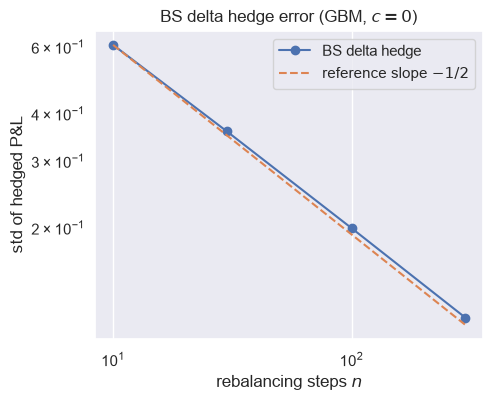

In [18]:
plot_std_vs_n(result, "BS delta hedge error (GBM, $c=0$)")

## BS hedging with transactions

*Same experiment with proportional cost c = 0.001: costs grow with n.*

In [19]:
## BS delta hedge on GBM with transaction costs
result = bs_hedge_vs_n(c=0.001)
result

,n,mean,std,VaR,CVaR
0,10,-0.197011,0.619515,1.244777,1.681916
1,30,-0.272316,0.377133,0.923204,1.188590
2,100,-0.419451,0.245588,0.870932,1.043720
3,300,-0.653111,0.246886,1.094680,1.221737


*Log-log plot of std vs n with costs.*

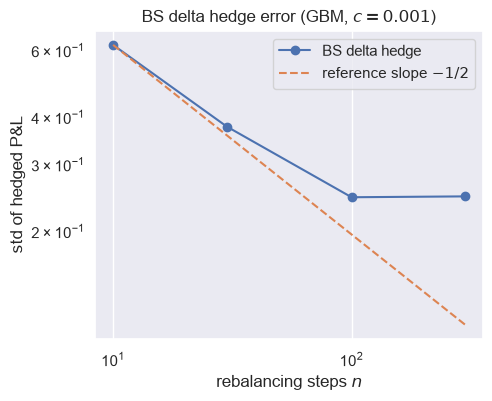

In [20]:
plot_std_vs_n(result, "BS delta hedge error (GBM, $c=0.001$)")

Takeaway message for the two experiments above:

 - Experiment 1, BS hedging with no transaction cost

    - The mean final pnl is approximately 0, so that on average we won't be losing money or earning money

    - The hedging error decreases with $n$ increases, roughly in $O(n^{1/2})$. 

- Experiment 2, BS hedging with $c=0.001$ transaction cost

    - The transaction costs increases with $n$, roughly in $O(n^{1/2})$, directly causing the mean final pnl failing below 0

    - The risk measure no longer decreases monotonically. Both obtain their lowest around $n\approx 100$ and increases for larger $n$

    - BS delta only yields a compromise between hedging error and transaction cost, so that there is no better way to get around.

## WW band hedging with c=0.001

*WW band vs n for gamma in {0.1, 1, 10} (first table).*

In [21]:
n_list = [10, 30, 100, 300]; gamma_list = [0.1, 1, 10]
T, K, sigma = 30 / 365, 100.0, 0.2
C = bs_price(100.0, K, T, sigma).item() 

torch.manual_seed(0)
rows = []
for n in n_list:
    S = simulate_gbm(100000, n_steps=n, dt=T / n, sigma=sigma)["S"][:, :, 0]   # (B, n+1)
    for gamma in gamma_list:
        pnl = bm.hedge_pnl(S, bm.ww_band_policy(K, sigma, 0.001, gamma), K, T, c=0.001, p0=C)   
        rows.append({"n": n, "gamma": gamma,  **bm.summarize(pnl)})

result = pd.DataFrame(rows)
result

,n,gamma,mean,std,VaR,CVaR
0,10,0.1,-0.125897,1.069887,1.944529,2.352777
1,10,1.0,-0.149546,0.772071,1.389427,1.802426
2,10,10.0,-0.168092,0.663123,1.242882,1.663860
3,30,0.1,-0.137560,0.877768,1.550704,1.861218
4,30,1.0,-0.164403,0.564291,1.050051,1.345837
5,30,10.0,-0.197267,0.435748,0.907203,1.176708
6,100,0.1,-0.145420,0.760527,1.353241,1.621440
7,100,1.0,-0.180910,0.440055,0.870434,1.100692
8,100,10.0,-0.232649,0.300955,0.738772,0.922177
9,300,0.1,-0.151480,0.706508,1.271711,1.529788


*WW band vs BS delta for several gamma and n on common random numbers; plot of mean / std / CVaR.*

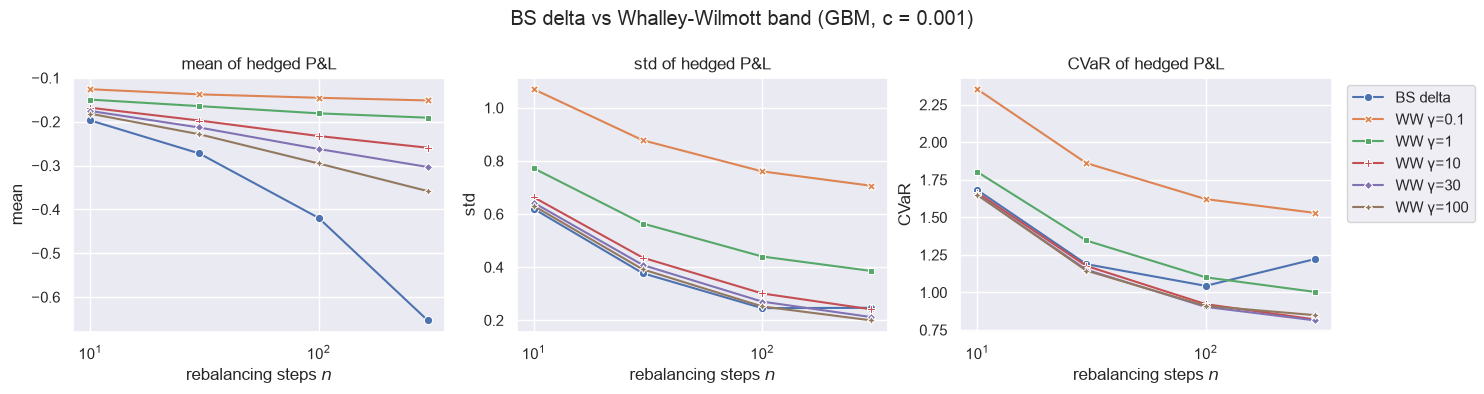

In [22]:
n_list = [10, 30, 100, 300]
gamma_list = [0.1, 1, 10, 30, 100]
T, K, sigma, c = 30 / 365, 100.0, 0.2, 0.001
C = bs_price(100.0, K, T, sigma).item()

torch.manual_seed(0)
rows = []
for n in n_list:
    # simulate once per n: every policy is evaluated on the same paths (common random numbers)
    S = simulate_gbm(100_000, n_steps=n, dt=T / n, sigma=sigma)["S"][:, :, 0]
    policies = {"BS delta": bm.bs_delta_policy(K, sigma)}
    policies.update({f"WW γ={g}": bm.ww_band_policy(K, sigma, c, g) for g in gamma_list})
    for name, policy in policies.items():
        pnl = bm.hedge_pnl(S, policy, K, T, c=c, p0=C)
        rows.append({"n": n, "policy": name, **bm.summarize(pnl)})

result_ww = pd.DataFrame(rows)

plot_metrics_vs_n(result_ww, f"BS delta vs Whalley-Wilmott band (GBM, c = {c})")

## BS hedging on Heston paths

*M3 benchmark: on Heston paths, BS delta with fixed sigma vs BS delta with the current sqrt(V_k), vs n.*

In [23]:
n_list = [10, 30, 100, 300]
T, K = 30/365, 100.0
params = HestonParams()                      # paper parameters, shared by simulation and pricing
C_heston = heston_price(K=K, T=T, params=params)
sigma_bar = params.b ** 0.5                  # fixed vol for the plain BS delta = sqrt(long-run variance) = 0.2
C_bs = bs_price(100.0, K, T, sigma_bar).item()

torch.manual_seed(0)
rows = []
for n in n_list:
    # Heston paths: both policies are evaluated on the same paths
    out = simulate_heston(100000, n_steps=n, dt=T/n, params=params)
    S, V = out["S"][:, :, 0], out["V"]       # (B, n+1)
    heston_policies = {
        "Heston: BS delta, fixed σ": bm.bs_delta_policy(K, sigma_bar),
        "Heston: BS delta, √V_k":    bm.bs_delta_stovol_policy(K),
    }
    for name, policy in heston_policies.items():
        pnl = bm.hedge_pnl(S, policy, K, T, c=0, p0=C_heston, V=V)
        rows.append({"n": n, "policy": name, **bm.summarize(pnl)})

    # reference: BS delta on GBM paths with the same average vol (no vol risk)
    S_gbm = simulate_gbm(100000, n_steps=n, dt=T/n, sigma=sigma_bar)["S"][:, :, 0]
    pnl = bm.hedge_pnl(S_gbm, bm.bs_delta_policy(K, sigma_bar), K, T, c=0, p0=C_bs)
    rows.append({"n": n, "policy": "GBM: BS delta (reference)", **bm.summarize(pnl)})

result_heston = pd.DataFrame(rows)
result_heston.pivot(index="n", columns="policy", values="CVaR")

policy,GBM: BS delta (reference),"Heston: BS delta, fixed σ","Heston: BS delta, √V_k"
n,,,
10,1.430158,4.191977,4.174931
30,0.827901,3.820452,3.721371
100,0.460091,3.735880,3.551919
300,0.266736,3.670247,3.497805


*Plot mean / std / CVaR of the M3 benchmark policies vs n.*

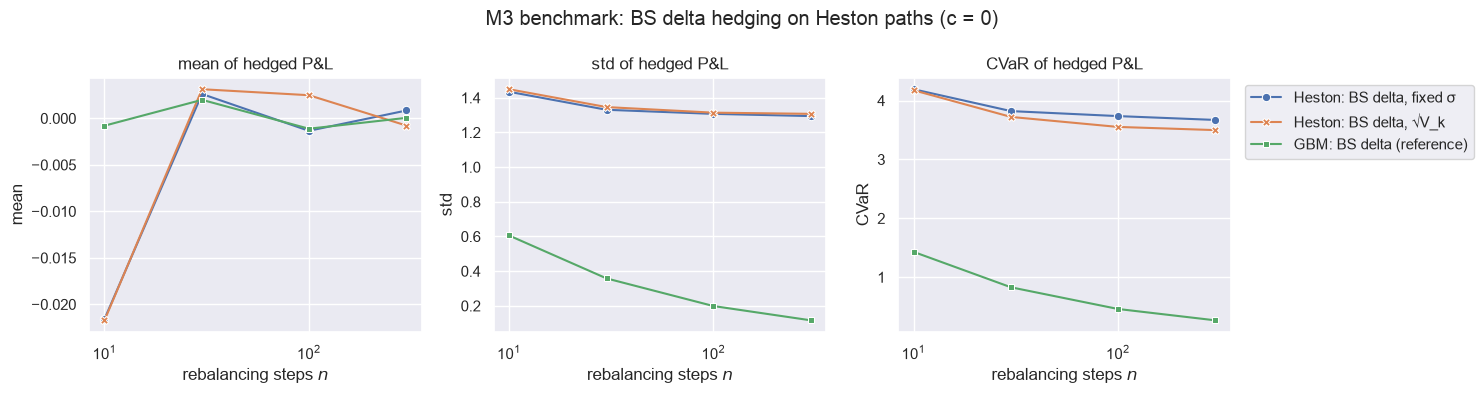

In [24]:
plot_metrics_vs_n(result_heston, "M3 benchmark: BS delta hedging on Heston paths (c = 0)")

## Heston Hedging on Heston Paths

*M4 benchmark: Heston complete hedge (delta in the stock + vega / dL/dv in the variance swap), vs M3.*

In [25]:
params = HestonParams()
T, K = 30 / 365, 100.0
n_list = [10, 30, 100, 300]
p0 = heston_price(K=K, T=T, params=params)

torch.manual_seed(0)
rows = []
for n in n_list:
    dt = T / n
    out = simulate_heston(20000, n_steps=n, dt=dt, params=params)
    S1, S2, V = out["S"][:, :, 0], out["S"][:, :, 1], out["V"]     # (B, n+1)

    # M4: Heston complete hedge with stock + variance swap
    gains = torch.zeros_like(S1[:, 0])                              # (B,)
    for k in range(n):
        tau_k = T - k * dt
        _, delta, vega = heston_greeks(S1[:, k], V[:, k], tau_k, K, params)
        dLdv = (1 - np.exp(-params.alpha * tau_k)) / params.alpha    # sensitivity of the variance swap to v
        d1, d2 = delta, vega / dLdv                                  # stock, variance swap holdings
        gains = gains + d1 * (S1[:, k+1] - S1[:, k]) + d2 * (S2[:, k+1] - S2[:, k])

    Z = (S1[:, -1] - K).clamp(min=0)                                 # call payoff, spot only
    pnl_m4 = p0 - Z + gains

    # M3 on the same paths: stock only, BS delta with sqrt(V_k)
    pnl_m3 = bm.hedge_pnl(S1, bm.bs_delta_stovol_policy(K), K, T, c=0, p0=p0, V=V)

    rows.append({"n": n, "policy": "M4: Heston complete hedge (stock + var swap)", **bm.summarize(pnl_m4)})
    rows.append({"n": n, "policy": "M3: BS delta with √V_k (stock only)", **bm.summarize(pnl_m3)})

result_m4 = pd.DataFrame(rows)
result_m4.pivot(index="n", columns="policy", values="std")

policy,M3: BS delta with √V_k (stock only),M4: Heston complete hedge (stock + var swap)
n,,
10,1.442538,0.635931
30,1.361706,0.383348
100,1.316187,0.213446
300,1.297558,0.124073


*Plot M3 vs M4: adding the variance swap removes most of the hedging error.*

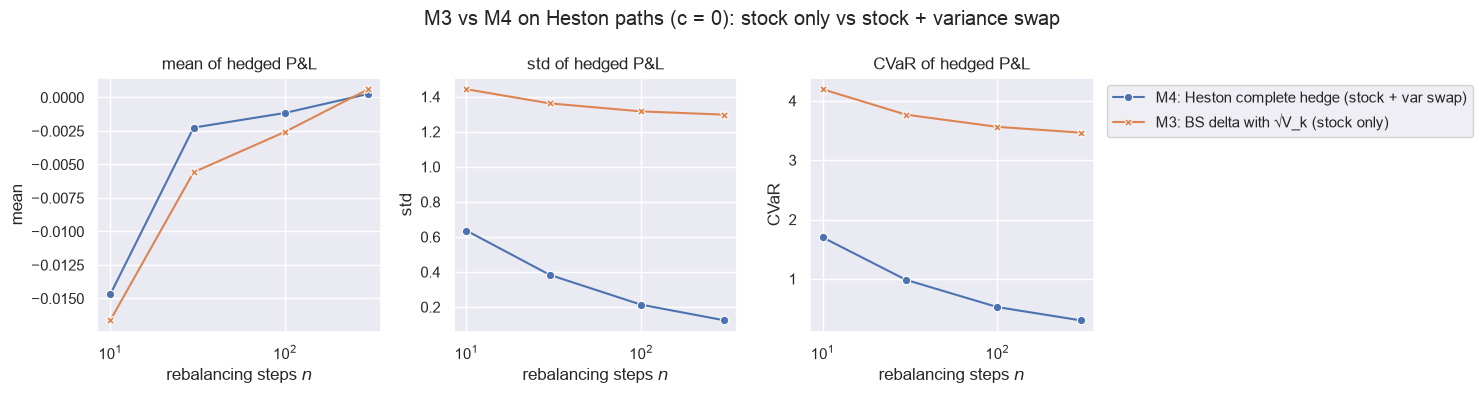

In [26]:
plot_metrics_vs_n(result_m4, "M3 vs M4 on Heston paths (c = 0): stock only vs stock + variance swap")